# Unidad 5 — Complejidad Algorítmica

**Programación Orientada a Objetos — ISTEA**

La complejidad algorítmica nos permite predecir cómo escala el rendimiento de un algoritmo
cuando crece el tamaño de la entrada. La notación Big O es el estándar para expresarla.

**Temas que practico en esta unidad:**
- Reconocer las complejidades: O(1), O(log n), O(n), O(n log n), O(n²), O(2^n)
- Medir tiempos reales con `time` y `timeit`
- Comparar búsqueda lineal vs binaria
- Comparar Bubble Sort vs sorted() de Python
- Comparar Fibonacci recursivo, iterativo y con memoización

*Consignas de la cátedra. Resoluciones desarrolladas durante la cursada.*

## Ejercicios

### 🟢 Ejercicio 1 — Identificar complejidad
Identificar la complejidad Big O de cada fragmento de código.


In [1]:
# 🎯 EJERCICIO 1: Identificar la complejidad de cada función

def funcion_a(lista):
    return lista[0]  # O(1): un solo acceso por índice, no depende del tamaño

def funcion_b(lista):
    for elem in lista:
        print(elem)  # O(n): recorre la lista una vez

def funcion_c(n):
    while n > 1:
        n = n // 2  # O(log n): n se divide a la mitad en cada vuelta

def funcion_d(lista):
    for i in lista:
        for j in lista:
            print(i, j)  # O(n²): por cada elemento recorre toda la lista otra vez

def funcion_e(n):
    if n <= 0:
        return 1
    return funcion_e(n-1) + funcion_e(n-1)  # O(2^n): cada llamada genera dos más

for nombre, complejidad in [("funcion_a", "O(1)"), ("funcion_b", "O(n)"), ("funcion_c", "O(log n)"),
                            ("funcion_d", "O(n²)"), ("funcion_e", "O(2^n)")]:
    print(f"{nombre}: {complejidad}")

funcion_a: O(1)
funcion_b: O(n)
funcion_c: O(log n)
funcion_d: O(n²)
funcion_e: O(2^n)


### 🟡 Ejercicio 2 — Comparar suma para 1M elementos
Comparar: suma con for loop vs sum() vs numpy.sum() para 1,000,000 elementos.


In [2]:
# 🎯 EJERCICIO 2: Comparar formas de sumar 1M elementos
import time
import numpy as np

numeros = list(range(1_000_000))
arreglo = np.array(numeros)

def suma_con_for(lista):
    total = 0
    for n in lista:
        total += n
    return total

tiempos = {}
for nombre, funcion in [("for loop", lambda: suma_con_for(numeros)),
                        ("sum()", lambda: sum(numeros)),
                        ("np.sum()", lambda: np.sum(arreglo))]:
    inicio = time.perf_counter()
    resultado = funcion()
    tiempos[nombre] = (time.perf_counter() - inicio) * 1000
    print(f"{nombre:<9}: {tiempos[nombre]:8.2f} ms   (resultado = {resultado:,})")

print(f"\nnp.sum() es ~{tiempos['for loop'] / tiempos['np.sum()']:.0f} veces más rápido que el for")

for loop :    15.98 ms   (resultado = 499,999,500,000)
sum()    :     5.73 ms   (resultado = 499,999,500,000)
np.sum() :     0.50 ms   (resultado = 499,999,500,000)

np.sum() es ~32 veces más rápido que el for


### 🟡 Ejercicio 3 — Búsqueda binaria desde cero
Implementar búsqueda binaria en una lista ordenada.


In [3]:
# 🎯 EJERCICIO 3: Implementar búsqueda binaria
def busqueda_binaria_propia(lista_ordenada, objetivo):
    izquierda, derecha = 0, len(lista_ordenada) - 1
    while izquierda <= derecha:
        medio = (izquierda + derecha) // 2
        if lista_ordenada[medio] == objetivo:
            return medio
        elif lista_ordenada[medio] < objetivo:
            izquierda = medio + 1    # el objetivo está en la mitad derecha
        else:
            derecha = medio - 1      # el objetivo está en la mitad izquierda
    return -1

# Pruebas:
numeros = list(range(0, 200, 2))  # [0, 2, 4, 6, ..., 198]
print(busqueda_binaria_propia(numeros, 128))  # → índice 64
print(busqueda_binaria_propia(numeros, 99))   # → -1 (no existe)

64
-1


### 🔴 Ejercicio 4 — Bubble sort vs sorted()
Comparar tiempos de Bubble Sort vs sorted() para n = 100, 1000, 5000.


In [4]:
# 🎯 EJERCICIO 4: Comparación de ordenamiento
import random, time

def mi_bubble_sort(lista):
    lst = lista.copy()          # no modifico la lista original
    n = len(lst)
    for i in range(n):
        for j in range(n - i - 1):
            if lst[j] > lst[j + 1]:
                lst[j], lst[j + 1] = lst[j + 1], lst[j]
    return lst

random.seed(42)
print(f"{'n':>6} | {'Bubble Sort':>12} | {'sorted()':>10} | {'Factor':>7}")
print("-" * 46)
for n in [100, 1000, 5000]:
    datos = [random.randint(0, 10_000) for _ in range(n)]

    inicio = time.perf_counter()
    resultado_bubble = mi_bubble_sort(datos)
    t_bubble = (time.perf_counter() - inicio) * 1000

    inicio = time.perf_counter()
    resultado_sorted = sorted(datos)
    t_sorted = (time.perf_counter() - inicio) * 1000

    assert resultado_bubble == resultado_sorted   # verifico que los dos ordenen igual
    print(f"{n:>6} | {t_bubble:>10.2f}ms | {t_sorted:>8.4f}ms | {t_bubble / t_sorted:>6.0f}x")

     n |  Bubble Sort |   sorted() |  Factor
----------------------------------------------
   100 |       0.21ms |   0.0074ms |     28x
  1000 |      24.17ms |   0.0939ms |    257x


  5000 |     679.21ms |   0.4748ms |   1431x


### 🔴 Ejercicio 5 — Comparar 3 versiones de Fibonacci
Comparar Fibonacci recursivo (O(2^n)), iterativo (O(n)) y con @lru_cache.


In [5]:
# 🎯 EJERCICIO 5: Las 3 versiones de Fibonacci
from functools import lru_cache
import time

def fib_recursivo(n):            # O(2^n)
    if n <= 1:
        return n
    return fib_recursivo(n - 1) + fib_recursivo(n - 2)

def fib_iterativo(n):            # O(n)
    a, b = 0, 1
    for _ in range(n):
        a, b = b, a + b
    return a

@lru_cache(maxsize=None)
def fib_memo(n):                 # O(n): guarda los resultados ya calculados
    if n <= 1:
        return n
    return fib_memo(n - 1) + fib_memo(n - 2)

def medir(funcion, n):
    inicio = time.perf_counter()
    resultado = funcion(n)
    return resultado, (time.perf_counter() - inicio) * 1000

print(f"{'n':>4} | {'Recursivo':>12} | {'Iterativo':>11} | {'Memoizado':>11}")
print("-" * 48)
for n in [10, 20, 30]:
    fib_memo.cache_clear()       # para que la memoización arranque de cero
    r1, t1 = medir(fib_recursivo, n)
    r2, t2 = medir(fib_iterativo, n)
    r3, t3 = medir(fib_memo, n)
    assert r1 == r2 == r3
    print(f"{n:>4} | {t1:>10.3f}ms | {t2:>9.4f}ms | {t3:>9.4f}ms")

print(f"\nfib(30) = {fib_iterativo(30)}")

   n |    Recursivo |   Iterativo |   Memoizado
------------------------------------------------
  10 |      0.007ms |    0.0015ms |    0.0038ms
  20 |      0.551ms |    0.0015ms |    0.0052ms
  30 |     66.971ms |    0.0036ms |    0.0152ms

fib(30) = 832040


## Desafío extra 🔴

Implementar y comparar **Merge Sort** (O(n log n)) vs **Bubble Sort** (O(n²)).
- Implementar Merge Sort recursivo desde cero
- Medir ambos para n = 100, 1000, 5000, 10000
- Graficar si matplotlib disponible
- Calcular la relación teórica n²/(n log₂n) y compararla con la relación medida


     n |     Merge |     Bubble | Relación medida | n²/(n·log₂n)
------------------------------------------------------------------
   100 |     0.1ms |      0.2ms |              3x |          15x
  1000 |     0.9ms |     23.3ms |             27x |         100x


  5000 |     5.3ms |    657.1ms |            124x |         407x


 10000 |    11.5ms |   2741.3ms |            237x |         753x


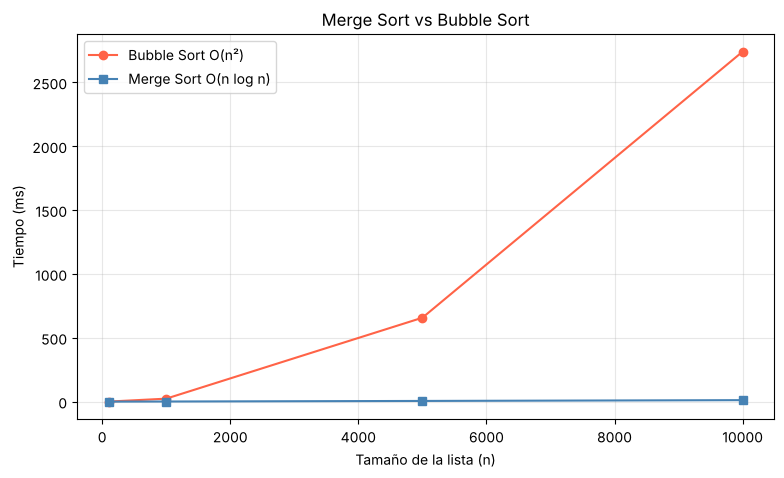

In [6]:
# 🔴 Desafío: Merge Sort vs Bubble Sort
import time, random, math
import matplotlib.pyplot as plt

def merge_sort(lista):
    if len(lista) <= 1:
        return lista
    medio = len(lista) // 2
    izquierda = merge_sort(lista[:medio])
    derecha = merge_sort(lista[medio:])
    # Merge: voy tomando el menor de cada mitad
    resultado, i, j = [], 0, 0
    while i < len(izquierda) and j < len(derecha):
        if izquierda[i] <= derecha[j]:
            resultado.append(izquierda[i]); i += 1
        else:
            resultado.append(derecha[j]); j += 1
    resultado.extend(izquierda[i:])
    resultado.extend(derecha[j:])
    return resultado

def bubble_sort_simple(lista):
    lst = lista.copy()
    n = len(lst)
    for i in range(n):
        for j in range(n - i - 1):
            if lst[j] > lst[j+1]:
                lst[j], lst[j+1] = lst[j+1], lst[j]
    return lst

random.seed(42)
tamanios = [100, 1000, 5000, 10000]
t_merge, t_bubble = [], []

print(f"{'n':>6} | {'Merge':>9} | {'Bubble':>10} | {'Relación medida':>15} | {'n²/(n·log₂n)':>12}")
print("-" * 66)
for n in tamanios:
    datos = [random.randint(0, 100_000) for _ in range(n)]
    inicio = time.perf_counter(); r_merge = merge_sort(datos); tm = time.perf_counter() - inicio
    inicio = time.perf_counter(); r_bubble = bubble_sort_simple(datos); tb = time.perf_counter() - inicio
    assert r_merge == r_bubble == sorted(datos)
    t_merge.append(tm * 1000); t_bubble.append(tb * 1000)
    teorica = n**2 / (n * math.log2(n))
    print(f"{n:>6} | {tm*1000:>7.1f}ms | {tb*1000:>8.1f}ms | {tb/tm:>14.0f}x | {teorica:>11.0f}x")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(tamanios, t_bubble, "o-", label="Bubble Sort O(n²)", color="tomato")
ax.plot(tamanios, t_merge, "s-", label="Merge Sort O(n log n)", color="steelblue")
ax.set_xlabel("Tamaño de la lista (n)")
ax.set_ylabel("Tiempo (ms)")
ax.set_title("Merge Sort vs Bubble Sort")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## Resumen de conceptos

| Complejidad | Nombre | Crecimiento para n=1M |
|---|---|---|
| O(1) | Constante | 1 operación |
| O(log n) | Logarítmica | ~20 operaciones |
| O(n) | Lineal | 1,000,000 operaciones |
| O(n log n) | Linealítmica | ~20,000,000 operaciones |
| O(n²) | Cuadrática | 10¹² operaciones |
| O(2^n) | Exponencial | Inviable para n>50 |

**Herramientas de medición:** `time.perf_counter()`, `timeit.timeit()`, `functools.lru_cache`
